### Supervised Learning

| S.No | Algorithm | Type | Mode |
|---|---|---|---|
| **5 ⭐** | **K-Nearest Neighbors (KNN)** | **Classification** | **Supervised** |


### **First, understand the problem**

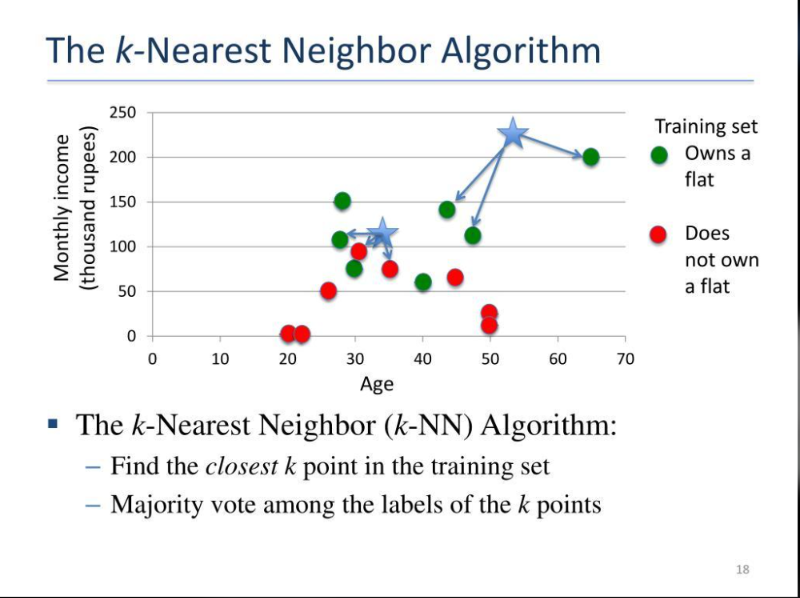

Imagine a bank wants to predict:

Will a person own a house or not?

The bank has information about previous customers.
- Monthly income.
- Number of working family members.
- Whether they own a house.

In your image:
- Green (+) = Own a House.
- Red (−) = Does not own a House.
- Yellow (?) = New customer whose result we don't know.

Suppose the new customer has:
- Monthly income = ₹30,000.
- Working family members = 2.
The question is: Does this person belong to the green group or red group?

This is where KNN comes in.

### **What is the logic behind KNN?**

KNN follows a very simple idea:

People who are similar to each other are likely to have similar outcomes.

Imagine you move to a new area and want to know whether people there own houses.

You check the 3 people living nearest to you.
- Person 1 owns a house.
- Person 2 owns a house.
- Person 3 rents a house.
Two out of three own houses.

So, you predict that you are more likely to own a house.

KNN does almost exactly this using mathematics.

### **What does K mean?**

K means the number of nearest neighbours we want to check.

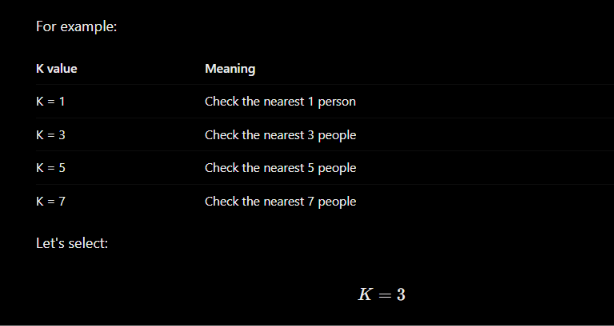

Our algorithm will find the 3 closest customers to the new customer.

### **Mathematics behind KNN**

This is the most important part.

KNN uses a mathematical formula called Euclidean Distance.

It measures the straight-line distance between two points.

Remember this order:
1. Subtract.
2. Square.
3. Add.
4. Square root.

### **Use Euclidean Distance.**

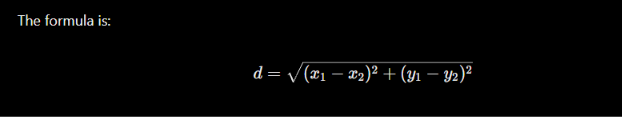

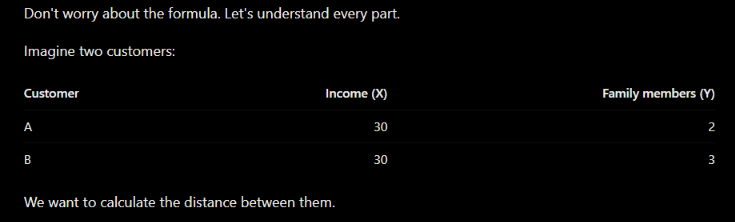

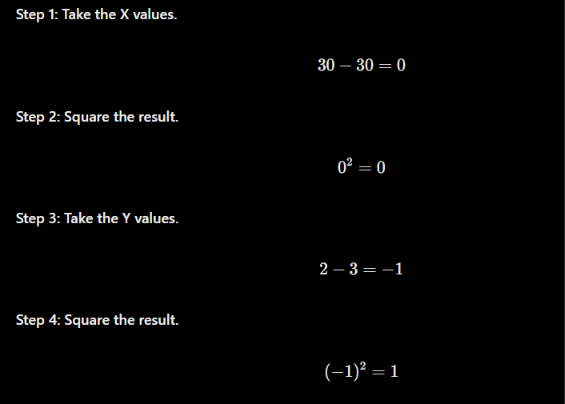

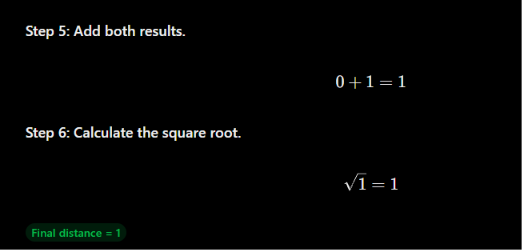

This means these two customers are only 1 unit apart.

### **Calculate the 3 nearest neighbours**

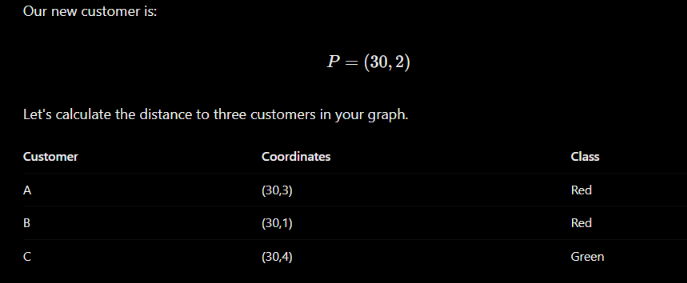

### **Use Euclidean Distance.**

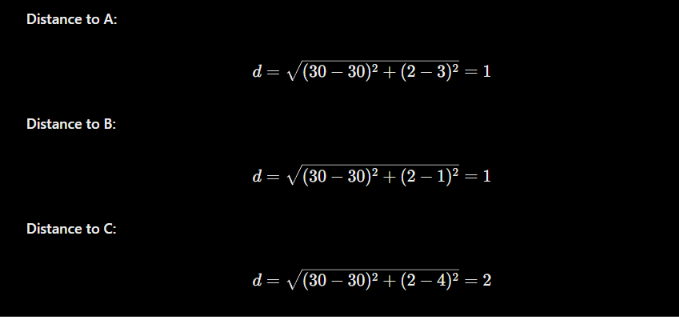

Now arrange the distances:

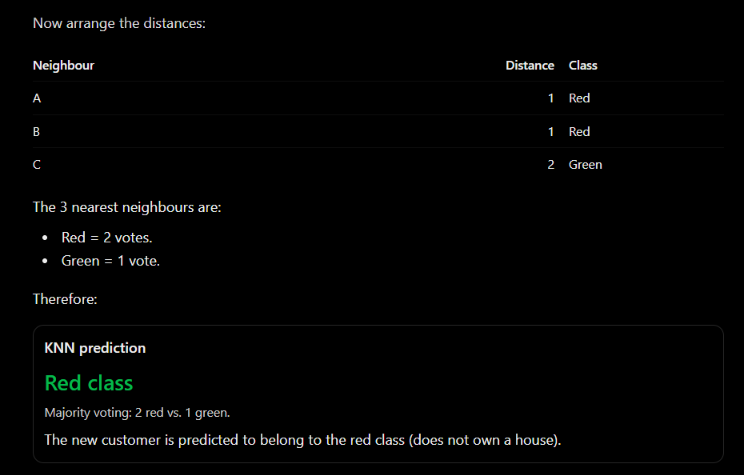

This process is called Majority Voting.

### **Test your understanding**

Let's see whether you understand the mathematical logic.

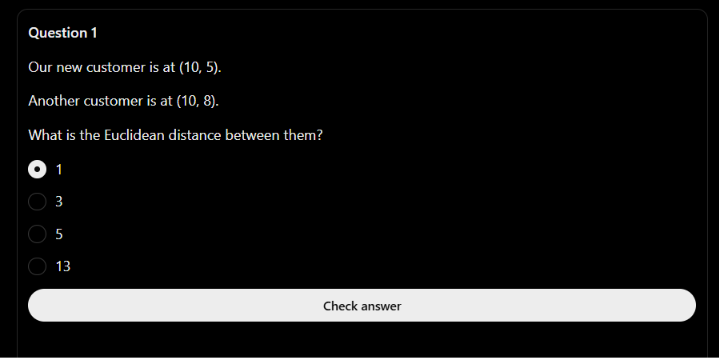

Let's calculate step by step.

Given:
- Point 1 = (10, 5)
- Point 2 = (10, 8)

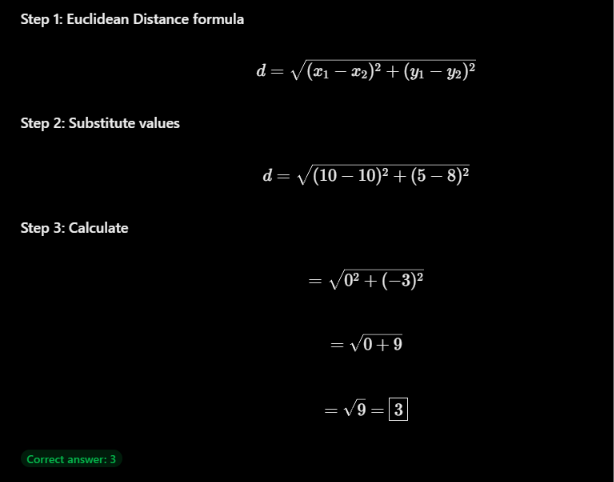

Remember this order:
1. Subtract.
2. Square.
3. Add.
4. Square root.

### **Complete KNN mathematical workflow**

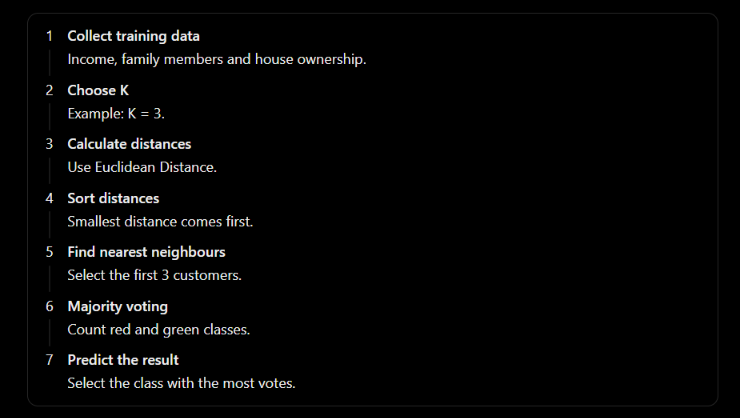

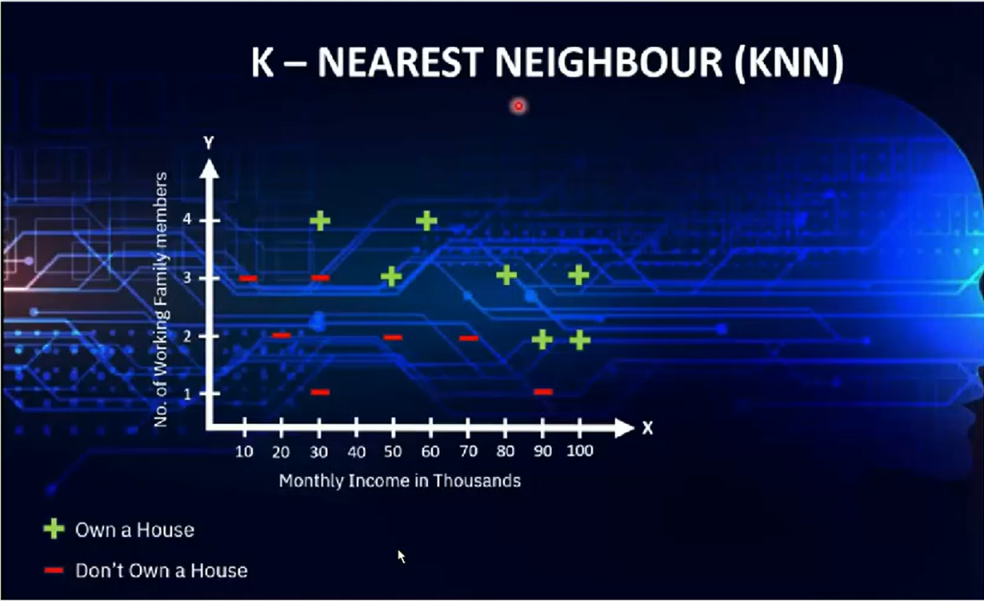

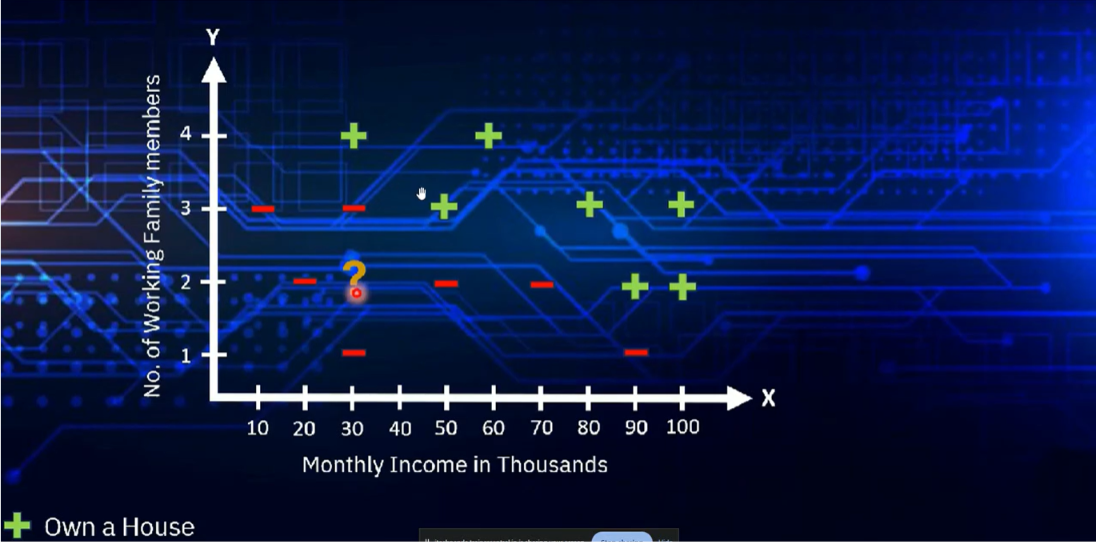

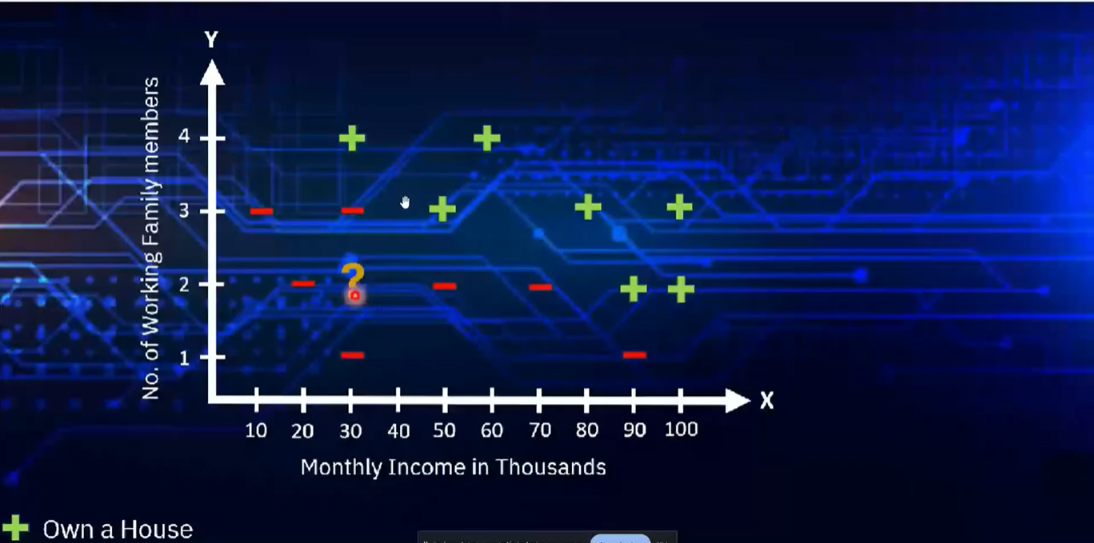

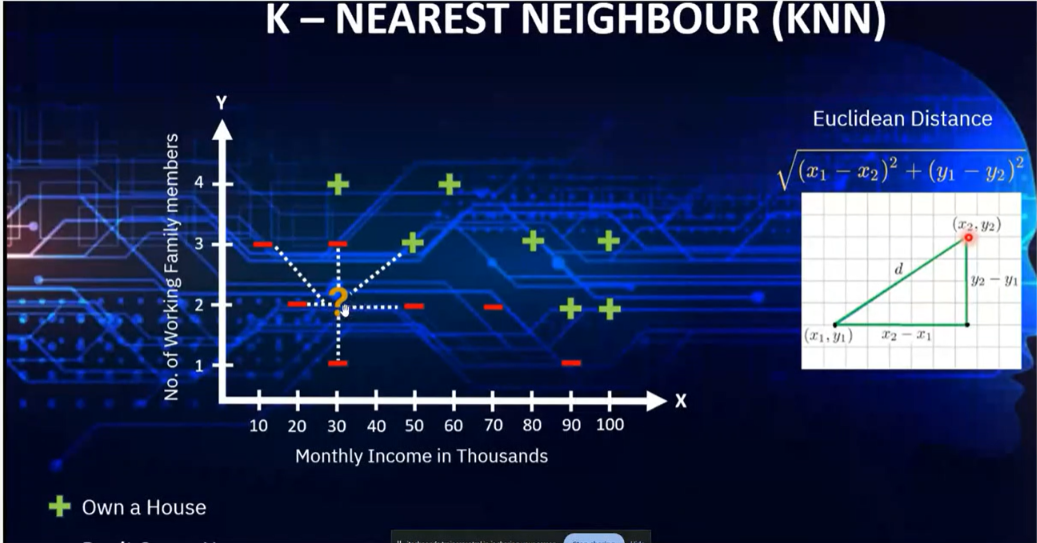

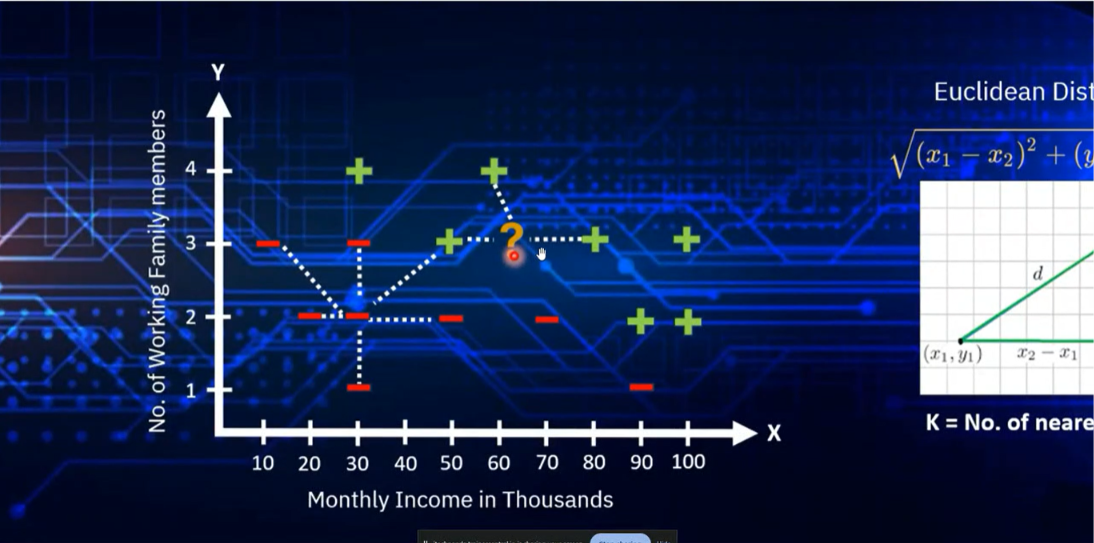

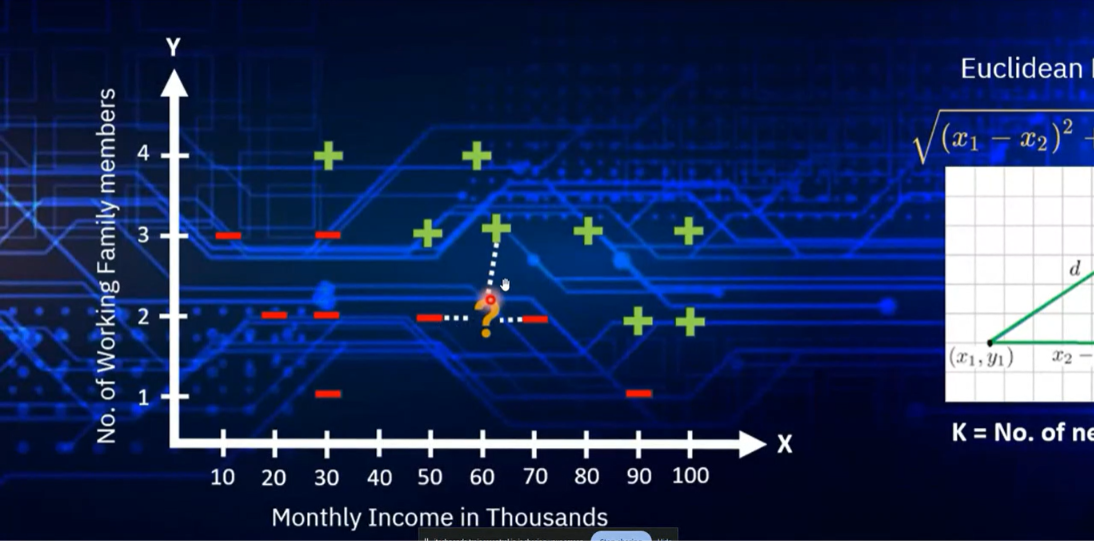

### **KNN_Model**

In [5]:
import pandas as pd
tel_data = pd.read_csv("C:\\Users\\Yesu\\OneDrive\\Documents\\Desktop\\telescope_data.csv")
tel_data.head()

,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [6]:
tel_data.columns = [cols.lower() for cols in tel_data.columns]
tel_data.head()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [7]:
tel_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   unnamed: 0  19020 non-null  int64  
 1   flength     19020 non-null  float64
 2   fwidth      19020 non-null  float64
 3   fsize       19020 non-null  float64
 4   fconc       19020 non-null  float64
 5   fconc1      19020 non-null  float64
 6   fasym       19020 non-null  float64
 7   fm3long     19020 non-null  float64
 8   fm3trans    19020 non-null  float64
 9   falpha      19020 non-null  float64
 10  fdist       19020 non-null  float64
 11  class       19020 non-null  str    
dtypes: float64(10), int64(1), str(1)
memory usage: 1.8 MB


In [8]:
tel_data.describe()

,unnamed: 0,flength,fwidth,fsize,fconc,fconc1,fasym,fm3long,fm3trans,falpha,fdist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,9509.500000,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,5490.745396,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,0.000000,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,4754.750000,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,9509.500000,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,14264.250000,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,19019.000000,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


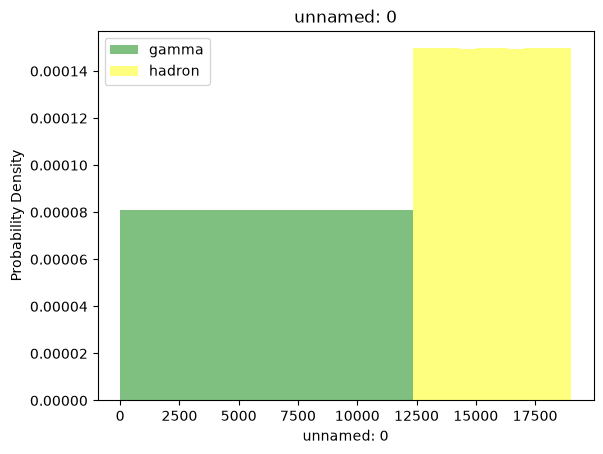

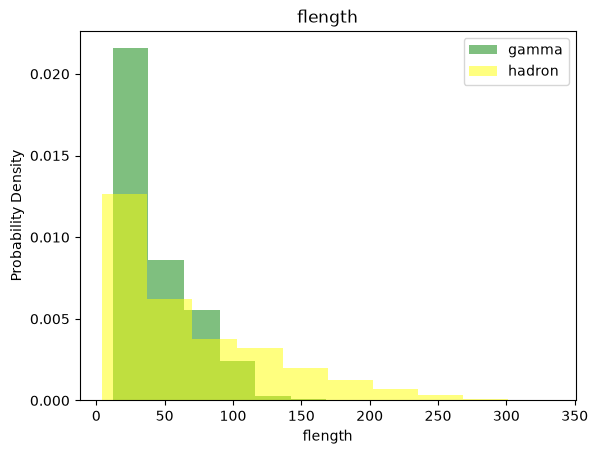

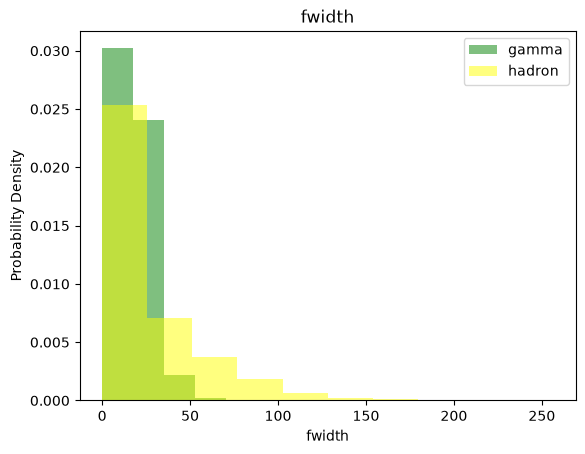

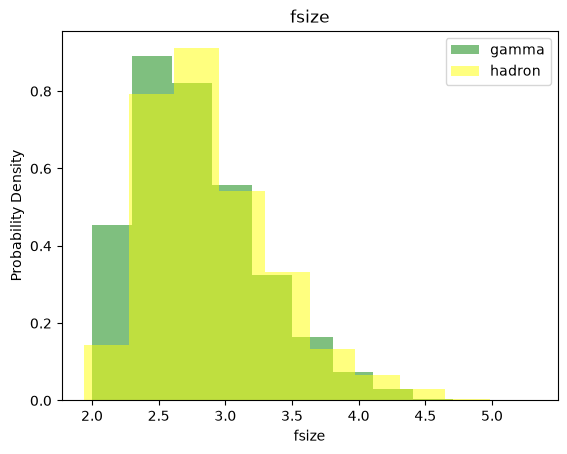

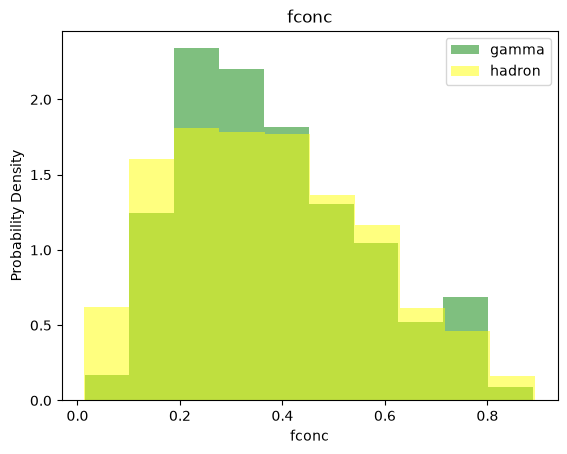

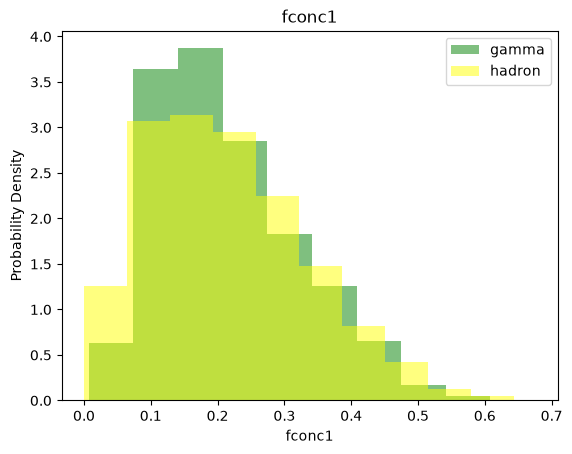

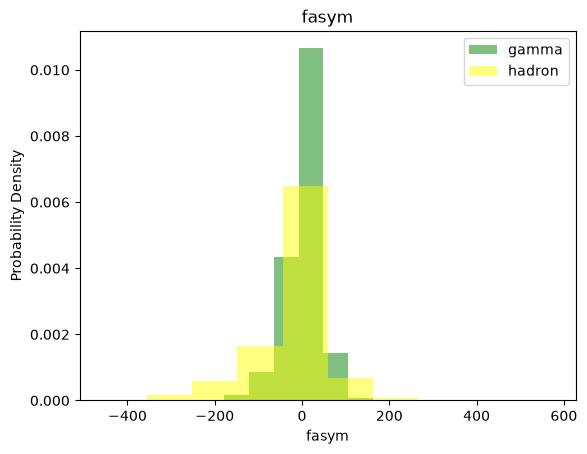

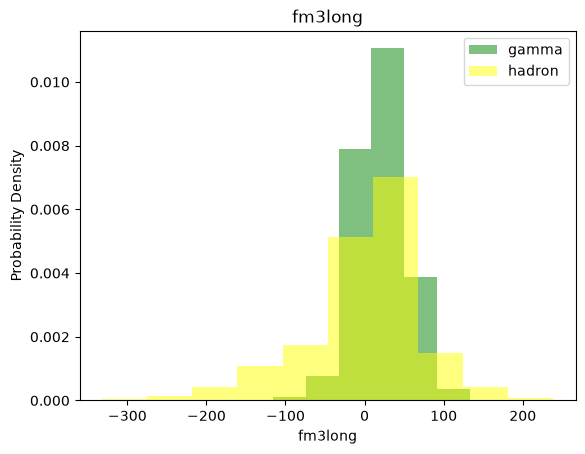

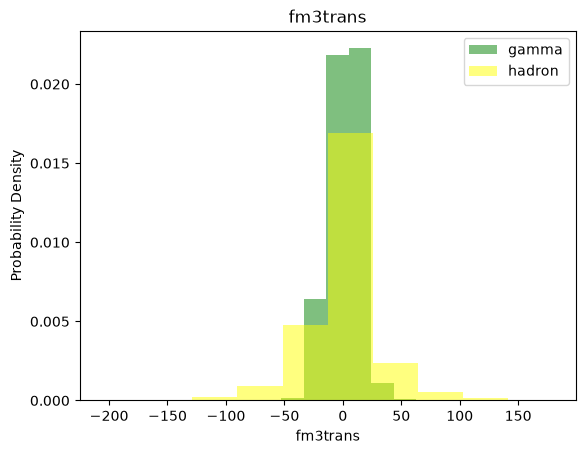

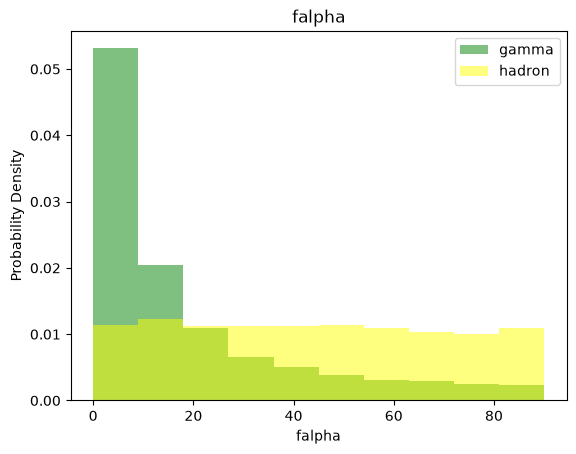

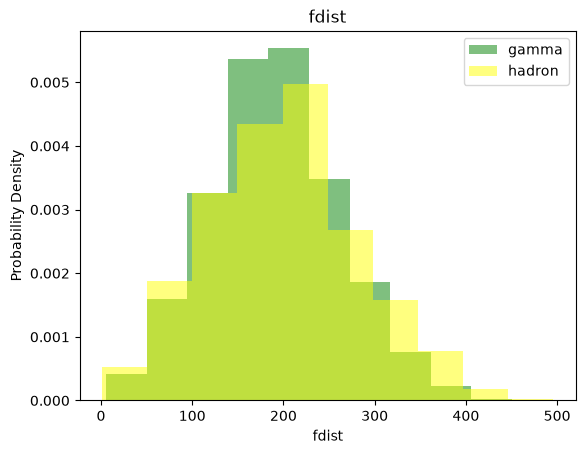

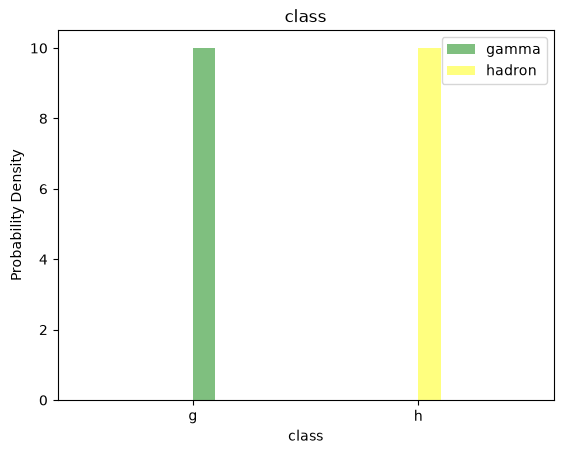

In [9]:
import matplotlib.pyplot as plt

for label in tel_data.columns:

    plt.hist(
        tel_data[tel_data['class'] == 'g'][label],
        color="green",
        label="gamma",
        alpha=0.5,
        density=True
    )

    plt.hist(
        tel_data[tel_data['class'] == 'h'][label],
        color="yellow",
        label="hadron",
        alpha=0.5,
        density=True
    )

    plt.title(label)
    plt.ylabel("Probability Density")
    plt.xlabel(label)
    plt.legend()
    plt.show()

Your goal is to predict whether a particle belongs to:
- g = Gamma (positive class)
- h = Hadron (negative class)

You are also using Random Oversampling + StandardScaler + KNN to improve classification.

Let's understand the complete project step by step, including the logic behind each line.

### **Data spiliting in model**

#### **1. Split the dataset into training and testing**

Training data: Used to teach the ML model.



Testing data: Used to check how well the model predicts unseen data.

In [10]:
from sklearn.model_selection import train_test_split
ds_train,ds_test = train_test_split(tel_data,test_size=0.2)

### **2. Check the dataset size**

In [11]:
print(len(ds_train)) #80 train
print(len(ds_test)) #20 train

15216
3804


#### **Check class distribution**
#### **gamma and haydron signal speartions**

In [12]:
print(len(ds_train[ds_train["class"]=="g"]))
print(len(ds_train[ds_train["class"]=="h"]))

9847
5369


#### **input data and output data spilting**

### **4. Import RandomOverSampler**

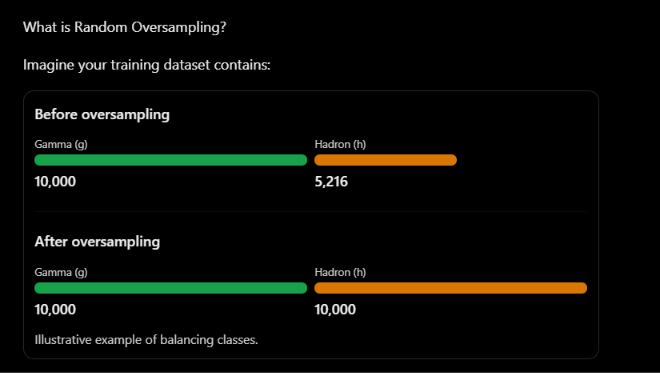

RandomOverSampler duplicates existing minority-class records until both classes have equal counts.

It does not create entirely new data.

In [ ]:
from imblearn.over_sampling import RandomOverSampler

r_ram = RandomOverSampler()

##  5. Separate input and output

in_ds_train = ds_train.drop(columns=["class"])
out_ds_train = ds_train["class"]

###  **5. Separate input and output**


This is one of the most important concepts in machine learning.

We separate the dataset into X and Y.

X = Input features
Y = Target

These are the 11 numerical columns used to predict the particle class.

For example:
- flength
- fwidth
- fsize
- fconc
- fasym
- fdist

Y = Target
g
h
g
g
h


In [57]:

##  5. Separate input and output

in_ds_train = ds_train.drop(columns=["class"])
out_ds_train = ds_train["class"]


In [15]:
print(in_ds_train)

       unnamed: 0   flength    fwidth   fsize   fconc  fconc1     fasym  \
17083       17083  117.7727   55.9569  2.9587  0.2763  0.1530 -140.9278   
1097         1097   37.8069   23.8420  3.3945  0.2048  0.1026   17.2787   
8920         8920   20.8415    7.1570  2.0700  0.7064  0.3532   24.5405   
6603         6603   18.1830   10.5409  2.2253  0.5893  0.3006  -23.3652   
12112       12112   76.2010   31.0262  3.3725  0.1824  0.0986  -25.9972   
...           ...       ...       ...     ...     ...     ...       ...   
18875       18875  228.2337  160.8347  4.2233  0.0228  0.0112 -179.9957   
7239         7239   20.2525   12.9894  2.2844  0.4935  0.2519  -14.6917   
7088         7088   72.3238   30.9529  3.4660  0.1549  0.0857  -19.4578   
7988         7988   88.5796   18.1558  2.9206  0.2665  0.1375 -106.1180   
18822       18822   33.3060   10.6203  2.4133  0.4324  0.2220    4.7813   

        fm3long  fm3trans   falpha     fdist  
17083   90.7397   37.0438  56.5301  305.8042  
1097 

In [16]:
print(out_ds_train)

17083    h
1097     g
8920     g
6603     g
12112    g
        ..
18875    h
7239     g
7088     g
7988     g
18822    h
Name: class, Length: 15216, dtype: str


###  **adding duplicates**

In [19]:
in_ds_train,out_ds_train = r_ram.fit_resample(in_ds_train,out_ds_train)
print(len(in_ds_train))
print(sum(out_ds_train == "g"))
print(sum(out_ds_train == "h"))

19694
9847
9847


### **test dataset**

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

in_ds_test = ds_test.drop(columns = ['class']) ## Separate input features (X)
out_ds_test=ds_test['class'] ## Separate target (Y)
in_ds_test= scaler.fit_transform(in_ds_test) ### Scaling

In [23]:
in_ds_test

array([[ 0.05822423,  0.02269504, -0.19058697, ...,  0.20901321,
        -0.93139135,  0.39974384],
       [-1.57011363,  0.37332753,  0.03915146, ..., -0.79430863,
        -0.82817449, -0.02962318],
       [-0.93965976, -0.43515486, -0.17505965, ..., -0.76879045,
        -0.65297267,  0.02030542],
       ...,
       [ 1.22585985, -0.60782026, -0.67861205, ...,  0.43256346,
        -0.92370649, -0.8404588 ],
       [ 0.52951314,  0.15291901,  0.37716056, ..., -0.79449358,
         1.04701138, -0.53654805],
       [ 1.05811604, -0.93381383, -0.63739531, ...,  0.55628539,
        -0.23150796,  0.06380515]], shape=(3804, 11))

In [24]:
print(len(in_ds_test))

3804


### **Build the KNN model**

In [53]:
from sklearn.neighbors import KNeighborsClassifier
Knn_model = KNeighborsClassifier(n_neighbors = 2)
Knn_model.fit(in_ds_train,out_ds_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['g','h']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### **Predict testing data**

In [54]:
out_pred = Knn_model.predict(in_ds_test)

c:\Users\Yesu\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [55]:
out_pred

array(['g', 'g', 'g', ..., 'g', 'g', 'g'], shape=(3804,), dtype=object)

### **Evaluate model accuracy**

In [56]:
from sklearn.metrics import accuracy_score
accuracy_info =accuracy_score(out_ds_test,out_pred)
accuracy_info

0.6532597266035752